# 03 - Fine-tuning CNN untuk Embedding Retrieval
Tujuan: melatih CNN (transfer learning) untuk mengklasifikasi 15 motif, lalu memakai embedding **sebelum layer klasifikasi** untuk pencarian cosine.

Aturan main:
- Split dan seed **sama persis** dengan notebook 02, jadi angka bisa dibandingkan langsung dengan baseline.
- Latih hanya di **galeri** (840). **Validation** (210) dipakai untuk memilih konfigurasi. **TEST tidak disentuh.**
- Setiap eksperimen otomatis dicatat ke `artifacts/results_finetune.csv` (bahan tabel laporan).
- `baseline_mAP` di tabel = embedding pretrained tanpa fine-tuning (epoch 0). Nilainya harus sama dengan hasil notebook 02.

**Revisi:** eksperimen "hanya melatih head" dihapus (embedding diambil sebelum head, jadi metrik retrieval tidak bisa berubah). Ditambah ronde 2 (30 epoch, perbandingan arsitektur yang lebih adil), pengulangan seed untuk kandidat terbaik, dan evaluasi TEST final satu kali.

In [1]:
import json, random, copy, time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DATA_DIR = Path("../data/raw")
MANIFEST = Path("../data/manifest.csv")
ART = Path("../artifacts")
for d in ["embeddings", "models", "history"]:
    (ART / d).mkdir(parents=True, exist_ok=True)
RESULTS_CSV = ART / "results_finetune.csv"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE, BATCH = 224, 32
print("device:", DEVICE)

device: cuda


In [2]:
import hashlib
v = json.load(open("../artifacts/data_version.json"))
assert hashlib.md5(MANIFEST.read_bytes()).hexdigest() == v["manifest_md5"], \
    "manifest.csv berubah sejak notebook 02. Jalankan ulang notebook 02."
print("manifest cocok dengan notebook 02:", v["n_train"], "train |", v["n_test"], "test")

manifest cocok dengan notebook 02: 1031 train | 295 test


## 1. Data (split sama dengan notebook 02)

In [3]:
EXT = {".jpg", ".jpeg", ".png"}

def build_manifest(data_dir):
    rows = []
    for split_dir in ["TRAIN", "TEST"]:
        for p in sorted((data_dir / split_dir).rglob("*")):
            if p.suffix.lower() in EXT:
                rows.append({"path": p.relative_to(data_dir).as_posix(),
                             "class": p.parent.name,
                             "split": split_dir.lower()})
    return pd.DataFrame(rows)

df = pd.read_csv(MANIFEST) if MANIFEST.exists() else build_manifest(DATA_DIR)

train_df = df[df["split"] == "train"].reset_index(drop=True)
tr_idx, val_idx = train_test_split(
    train_df.index, test_size=0.2, stratify=train_df["class"], random_state=SEED)
gallery_df = train_df.loc[tr_idx].reset_index(drop=True)
val_df = train_df.loc[val_idx].reset_index(drop=True)

classes = sorted(set(df["class"].tolist()))
cls2idx = {c: i for i, c in enumerate(classes)}
gl = np.array(gallery_df["class"].tolist())
ql = np.array(val_df["class"].tolist())
g_labels = np.array([cls2idx[c] for c in gl])

print(len(classes), "kelas |", len(gallery_df), "galeri |", len(val_df), "validation")
ref = json.load(open(ART / "embeddings" / "gallery_paths.json"))
assert gallery_df["path"].tolist() == ref, "Split galeri berbeda dengan notebook 02"

15 kelas | 824 galeri | 207 validation


## 2. Transformasi, dataset, dan model

In [4]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

eval_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

def make_train_tfm(augment):
    if not augment:
        return eval_tfm
    return transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(0.2, 0.2, 0.2, 0.02),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])

class ImgDS(Dataset):
    def __init__(self, frame, labels=None, tfm=eval_tfm):
        self.paths, self.labels, self.tfm = frame["path"].tolist(), labels, tfm
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        x = self.tfm(Image.open(DATA_DIR / self.paths[i]).convert("RGB"))
        return x if self.labels is None else (x, int(self.labels[i]))

class Net(nn.Module):
    """Backbone pretrained (tanpa classifier asli) + head klasifikasi 15 motif."""
    def __init__(self, name, n_classes):
        super().__init__()
        if name == "resnet50":
            b = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
            dim = b.fc.in_features; b.fc = nn.Identity()
        elif name == "mobilenet_v2":
            b = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)
            dim = b.classifier[1].in_features; b.classifier = nn.Identity()
        elif name == "efficientnet_b0":
            b = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
            dim = b.classifier[1].in_features; b.classifier = nn.Identity()
        else:
            raise ValueError(name)
        self.name, self.backbone = name, b
        self.head = nn.Sequential(nn.Dropout(0.2), nn.Linear(dim, n_classes))
    def embed(self, x):          # embedding untuk retrieval (sebelum head)
        return self.backbone(x)
    def forward(self, x):        # logit untuk klasifikasi saat training
        return self.head(self.backbone(x))

def blocks_of(net):
    b = net.backbone
    return [b.layer1, b.layer2, b.layer3, b.layer4] if net.name == "resnet50" else list(b.features)

def set_trainable(net, n_unfreeze):
    """Bekukan backbone, lalu buka n blok terakhir (0 = hanya head yang dilatih)."""
    for p in net.backbone.parameters():
        p.requires_grad = False
    if n_unfreeze > 0:
        for blk in blocks_of(net)[-n_unfreeze:]:
            for p in blk.parameters():
                p.requires_grad = True
    for p in net.head.parameters():
        p.requires_grad = True

def freeze_bn_of_frozen(net):
    """BatchNorm pada bagian yang dibekukan tetap mode eval agar statistiknya tidak berubah."""
    for m in net.backbone.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

## 3. Metrik retrieval (sama dengan notebook 02)

In [5]:
def precision_at_k(sims, q_labels, g_labels, k):
    idx = np.argsort(-sims, axis=1)[:, :k]
    return float((g_labels[idx] == q_labels[:, None]).mean())

def mean_ap(sims, q_labels, g_labels):
    aps = []
    for s, y in zip(sims, q_labels):
        rel = (g_labels[np.argsort(-s)] == y)
        if rel.sum() == 0:
            continue
        prec = np.cumsum(rel) / (np.arange(len(rel)) + 1)
        aps.append((prec * rel).sum() / rel.sum())
    return float(np.mean(aps))

@torch.no_grad()
def embed_frame(net, frame):
    net.eval()
    loader = DataLoader(ImgDS(frame), batch_size=BATCH, num_workers=0)
    f = np.concatenate([net.embed(x.to(DEVICE)).cpu().numpy() for x in loader])
    return f / np.linalg.norm(f, axis=1, keepdims=True)

def evaluate(net):
    g, q = embed_frame(net, gallery_df), embed_frame(net, val_df)
    sims = q @ g.T
    m = {"P@5": precision_at_k(sims, ql, gl, 5),
         "P@10": precision_at_k(sims, ql, gl, 10),
         "mAP": mean_ap(sims, ql, gl)}
    return m, g, q

## 4. Fungsi eksperimen

In [6]:
def run_experiment(cfg):
    """cfg: tag, backbone, n_unfreeze, optimizer ('adam'|'sgd'), lr (backbone), lr_head, augment, epochs."""
    t0, tag = time.time(), cfg["tag"]
    set_seed(cfg.get('seed', SEED))
    net = Net(cfg["backbone"], len(classes)).to(DEVICE)
    set_trainable(net, cfg["n_unfreeze"])

    groups = [{"params": list(net.head.parameters()), "lr": cfg["lr_head"]}]
    bb = [p for p in net.backbone.parameters() if p.requires_grad]
    if bb:
        groups.append({"params": bb, "lr": cfg["lr"]})
    opt = (torch.optim.Adam(groups) if cfg["optimizer"] == "adam"
           else torch.optim.SGD(groups, momentum=0.9, weight_decay=1e-4))

    loader = DataLoader(ImgDS(gallery_df, g_labels, make_train_tfm(cfg["augment"])),
                        batch_size=BATCH, shuffle=True, num_workers=0, drop_last=True)
    crit = nn.CrossEntropyLoss()

    m0, _, _ = evaluate(net)                       # epoch 0 = baseline pretrained
    history = [{"epoch": 0, "loss": None, **m0}]
    print(f"[{tag}] baseline  P@5={m0['P@5']:.4f}  mAP={m0['mAP']:.4f}")

    best = {"mAP": -1.0}
    for ep in range(1, cfg["epochs"] + 1):
        net.train(); freeze_bn_of_frozen(net)
        tot, n = 0.0, 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = crit(net(x), y)
            loss.backward(); opt.step()
            tot += loss.item() * len(y); n += len(y)
        m, g, q = evaluate(net)
        history.append({"epoch": ep, "loss": tot / n, **m})
        print(f"[{tag}] ep {ep:02d}  loss={tot/n:.4f}  P@5={m['P@5']:.4f}  mAP={m['mAP']:.4f}")
        if m["mAP"] > best["mAP"]:
            best = {**m, "epoch": ep}
            best_state, best_g, best_q = copy.deepcopy(net.state_dict()), g, q

    torch.save(best_state, ART / "models" / f"{tag}.pt")
    np.save(ART / "embeddings" / f"{tag}_gallery.npy", best_g)
    np.save(ART / "embeddings" / f"{tag}_val.npy", best_q)
    json.dump(history, open(ART / "history" / f"{tag}.json", "w"))

    row = {**cfg, "baseline_P@5": m0["P@5"], "baseline_mAP": m0["mAP"],
           "best_epoch": best["epoch"], "val_P@5": best["P@5"], "val_P@10": best["P@10"],
           "val_mAP": best["mAP"], "minutes": round((time.time() - t0) / 60, 1)}
    new = pd.DataFrame([row])
    if RESULTS_CSV.exists():
        old = pd.read_csv(RESULTS_CSV)
        new = pd.concat([old[old["tag"] != tag], new], ignore_index=True)
    new.to_csv(RESULTS_CSV, index=False)

    del net, opt, best_state
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return row

## 5. Rencana eksperimen
- **A (dihapus)**: melatih head saja tidak mengubah embedding backbone, jadi tidak relevan untuk retrieval. Cukup dijelaskan di laporan.
- **B**: membuka blok terakhir EfficientNet-B0 (optimizer, jumlah blok, learning rate). Sudah dijalankan di ronde 1.
- **C**: pembanding ResNet50 dan MobileNetV2 (ronde 1).
- **D (ronde 2)**: 30 epoch karena ronde 1 masih naik di epoch 15; variasi jumlah blok EfficientNet; ResNet50 dan MobileNetV2 dengan blok lebih banyak supaya perbandingan lebih adil; SGD dengan lr lebih besar.

Eksperimen yang `tag`-nya sudah ada di CSV dilewati.

In [7]:
EXPERIMENTS = [
    # ronde 1
    dict(tag="B1_eff_u2_adam",   backbone="efficientnet_b0", n_unfreeze=2, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=15),
    dict(tag="B2_eff_u2_sgd",    backbone="efficientnet_b0", n_unfreeze=2, optimizer="sgd",  lr=1e-3, lr_head=1e-2, augment=True,  epochs=15),
    dict(tag="B3_eff_u4_adam",   backbone="efficientnet_b0", n_unfreeze=4, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=15),
    dict(tag="B4_eff_u2_lowlr",  backbone="efficientnet_b0", n_unfreeze=2, optimizer="adam", lr=1e-5, lr_head=1e-3, augment=True,  epochs=15),
    dict(tag="C1_res_u1_adam",   backbone="resnet50",        n_unfreeze=1, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=15),
    dict(tag="C2_mob_u4_adam",   backbone="mobilenet_v2",    n_unfreeze=4, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=15),
    # ronde 2 (30 epoch)
    dict(tag="D1_eff_u4_30ep",   backbone="efficientnet_b0", n_unfreeze=4, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=30),
    dict(tag="D2_eff_u6_30ep",   backbone="efficientnet_b0", n_unfreeze=6, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=30),
    dict(tag="D3_eff_u9_30ep",   backbone="efficientnet_b0", n_unfreeze=9, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=30),
    dict(tag="D4_res_u3_30ep",   backbone="resnet50",        n_unfreeze=3, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=30),
    dict(tag="D5_mob_u8_30ep",   backbone="mobilenet_v2",    n_unfreeze=8, optimizer="adam", lr=1e-4, lr_head=1e-3, augment=True,  epochs=30),
    dict(tag="D6_eff_u4_sgd_hi", backbone="efficientnet_b0", n_unfreeze=4, optimizer="sgd",  lr=1e-2, lr_head=1e-2, augment=True,  epochs=30),
]

### Jalankan semua eksperimen (yang sudah tercatat di CSV dilewati, jadi aman diulang)

Total ronde 2 sekitar 20-25 menit di GPU. Kalau mau uji cepat dulu, jalankan `run_experiment(EXPERIMENTS[6])`.

In [8]:
done = set(pd.read_csv(RESULTS_CSV)["tag"]) if RESULTS_CSV.exists() else set()
for cfg in EXPERIMENTS:
    if cfg["tag"] in done:
        continue
    run_experiment(cfg)

[D5_mob_u8_30ep] baseline  P@5=0.5014  mAP=0.2387
[D5_mob_u8_30ep] ep 01  loss=2.3526  P@5=0.5246  mAP=0.2789
[D5_mob_u8_30ep] ep 02  loss=1.4872  P@5=0.5662  mAP=0.3484
[D5_mob_u8_30ep] ep 03  loss=0.9820  P@5=0.6097  mAP=0.4061
[D5_mob_u8_30ep] ep 04  loss=0.6943  P@5=0.6444  mAP=0.4471
[D5_mob_u8_30ep] ep 05  loss=0.5155  P@5=0.6696  mAP=0.4834
[D5_mob_u8_30ep] ep 06  loss=0.3970  P@5=0.6850  mAP=0.5075
[D5_mob_u8_30ep] ep 07  loss=0.3269  P@5=0.7014  mAP=0.5280
[D5_mob_u8_30ep] ep 08  loss=0.2182  P@5=0.7198  mAP=0.5448
[D5_mob_u8_30ep] ep 09  loss=0.2050  P@5=0.7314  mAP=0.5563
[D5_mob_u8_30ep] ep 10  loss=0.1559  P@5=0.7440  mAP=0.5683
[D5_mob_u8_30ep] ep 11  loss=0.1255  P@5=0.7411  mAP=0.5758
[D5_mob_u8_30ep] ep 12  loss=0.1160  P@5=0.7517  mAP=0.5861
[D5_mob_u8_30ep] ep 13  loss=0.0860  P@5=0.7575  mAP=0.5898
[D5_mob_u8_30ep] ep 14  loss=0.0783  P@5=0.7556  mAP=0.5952
[D5_mob_u8_30ep] ep 15  loss=0.0720  P@5=0.7556  mAP=0.6029
[D5_mob_u8_30ep] ep 16  loss=0.0523  P@5=0.7536  m

## 6. Tabel hasil untuk laporan

In [9]:
res = pd.read_csv(RESULTS_CSV)
res = res[~res["tag"].str.startswith("A")]          # A = head-only, tidak relevan untuk retrieval
res = res[~res["tag"].str.contains("_seed")]        # run ulang seed ada di bagian 9
cols = ["tag", "backbone", "n_unfreeze", "optimizer", "lr", "lr_head", "augment", "epochs",
        "best_epoch", "baseline_mAP", "val_P@5", "val_P@10", "val_mAP", "minutes"]
out = res[cols].sort_values("val_mAP", ascending=False).round(4)
out["lr"] = out["lr"].map(lambda v: f"{v:.0e}")
out["lr_head"] = out["lr_head"].map(lambda v: f"{v:.0e}")
out

,tag,backbone,n_unfreeze,optimizer,lr,lr_head,augment,epochs,best_epoch,baseline_mAP,val_P@5,val_P@10,val_mAP,minutes
11,D6_eff_u4_sgd_hi,efficientnet_b0,4,sgd,1e-02,1e-02,True,30,26,0.2716,0.8203,0.8024,0.7308,17.6
6,D1_eff_u4_30ep,efficientnet_b0,4,adam,1e-04,1e-03,True,30,30,0.2716,0.8155,0.7990,0.7238,3.7
7,D2_eff_u6_30ep,efficientnet_b0,6,adam,1e-04,1e-03,True,30,30,0.2716,0.8029,0.7903,0.7231,4.2
9,D4_res_u3_30ep,resnet50,3,adam,1e-04,1e-03,True,30,30,0.2579,0.8106,0.7874,0.6941,6.1
8,D3_eff_u9_30ep,efficientnet_b0,9,adam,1e-04,1e-03,True,30,30,0.2716,0.7749,0.7575,0.6840,4.9
2,B3_eff_u4_adam,efficientnet_b0,4,adam,1e-04,1e-03,True,15,15,0.2716,0.7884,0.7662,0.6756,1.7
10,D5_mob_u8_30ep,mobilenet_v2,8,adam,1e-04,1e-03,True,30,30,0.2387,0.7855,0.7599,0.6533,5.7
4,C1_res_u1_adam,resnet50,1,adam,1e-04,1e-03,True,15,15,0.2579,0.7575,0.7406,0.6441,2.5
5,C2_mob_u4_adam,mobilenet_v2,4,adam,1e-04,1e-03,True,15,15,0.2387,0.7227,0.6889,0.5473,1.6
0,B1_eff_u2_adam,efficientnet_b0,2,adam,1e-04,1e-03,True,15,15,0.2716,0.7101,0.6498,0.4984,1.6


## 7. Kurva training (loss dan metrik per epoch)

konfigurasi terbaik: D6_eff_u4_sgd_hi


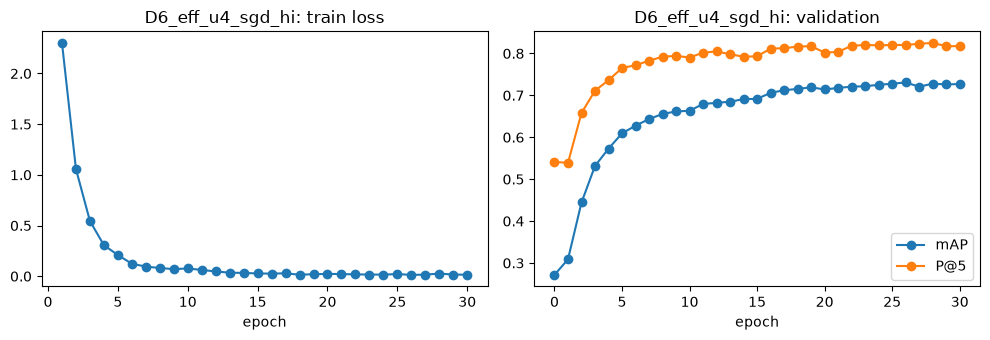

In [10]:
def plot_history(tag):
    h = pd.DataFrame(json.load(open(ART / "history" / f"{tag}.json")))
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(h["epoch"], h["loss"], marker="o"); ax[0].set_title(f"{tag}: train loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(h["epoch"], h["mAP"], marker="o", label="mAP")
    ax[1].plot(h["epoch"], h["P@5"], marker="o", label="P@5")
    ax[1].set_title(f"{tag}: validation"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

best_tag = res.sort_values("val_mAP", ascending=False).iloc[0]["tag"]
print("konfigurasi terbaik:", best_tag)
plot_history(best_tag)

## 8. Analisis kegagalan (bahan laporan)

In [11]:
g = np.load(ART / "embeddings" / f"{best_tag}_gallery.npy")
q = np.load(ART / "embeddings" / f"{best_tag}_val.npy")
top1 = (q @ g.T).argmax(axis=1)
pred = gl[top1]
print("Top-1 benar:", round(float((pred == ql).mean()), 4))

pd.Series([f"{a} -> {b}" for a, b in zip(ql, pred) if a != b]).value_counts().head(10)

Top-1 benar: 0.8406


Batik Bali -> Batik Sekar Jagad              3
Batik Betawi -> Batik Pala                   3
Batik Pala -> Batik Bali                     2
Batik Lasem -> Batik Kawung                  2
Batik Betawi -> Batik Tambal                 2
Batik Geblek Renteng -> Batik Dayak          2
Batik Lasem -> Batik Dayak                   2
Batik Betawi -> Batik Lasem                  1
Batik Ikat Celup -> Batik Geblek Renteng     1
Batik Geblek Renteng -> Batik Cendrawasih    1
Name: count, dtype: int64

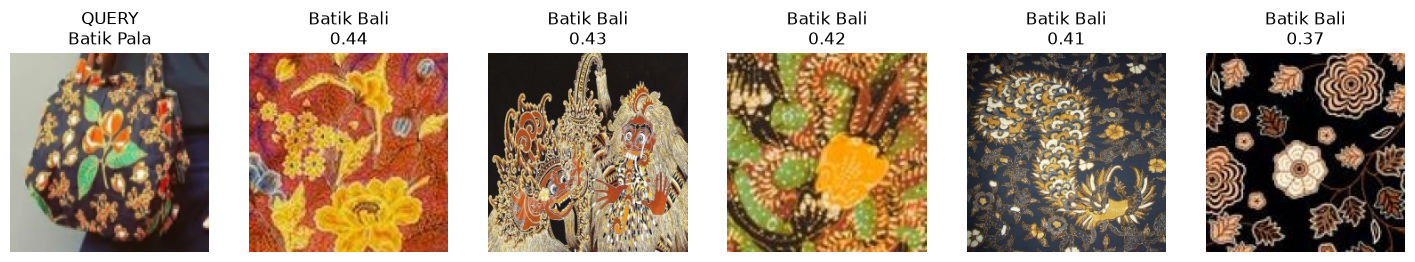

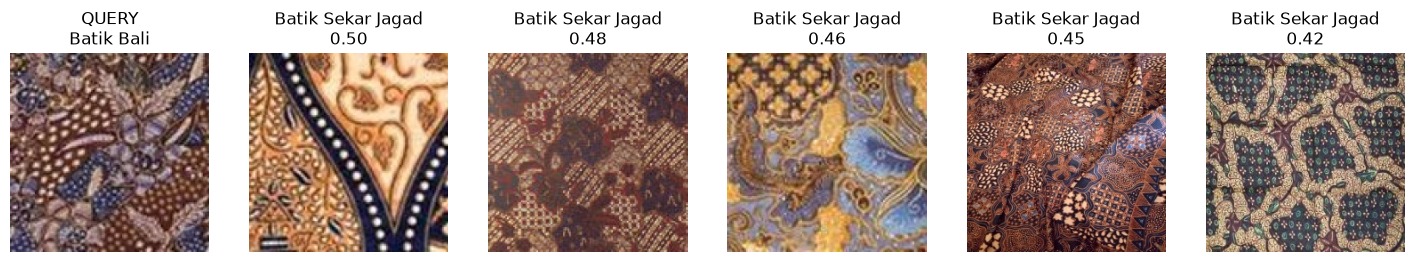

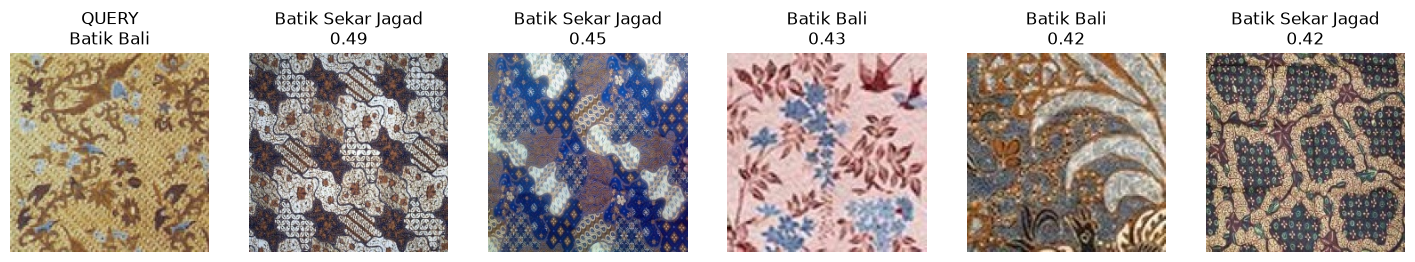

In [12]:
def show_query(i, g, q, k=5):
    sims = (q[i:i+1] @ g.T)[0]
    idx = np.argsort(-sims)[:k]
    fig, ax = plt.subplots(1, k + 1, figsize=(3 * (k + 1), 3))
    ax[0].imshow(Image.open(DATA_DIR / val_df["path"][i])); ax[0].set_title("QUERY\n" + ql[i])
    for j, gi in enumerate(idx, 1):
        ax[j].imshow(Image.open(DATA_DIR / gallery_df["path"][gi]))
        ax[j].set_title(f"{gl[gi]}\n{sims[gi]:.2f}")
    for a in ax: a.axis("off")
    plt.show()

bad = np.where(pred != ql)[0]
for i in bad[:3]:
    show_query(i, g, q)

## 9. Ulangi seed untuk kandidat teratas
Selisih kecil antar konfigurasi bisa kebetulan. Dua konfigurasi dengan `val_mAP` tertinggi diulang dengan 2 seed lain (seed 42 = hasil di atas), lalu dilaporkan rata-rata ± simpangan baku. `best_epoch` yang dilaporkan di sini juga dipakai sebagai acuan jumlah epoch di langkah final.

In [13]:
SEEDS_EXTRA = [7, 123]
by_tag = {c["tag"]: c for c in EXPERIMENTS}
top2 = res.sort_values("val_mAP", ascending=False)["tag"].head(2).tolist()
print("kandidat:", top2)

done = set(pd.read_csv(RESULTS_CSV)["tag"])
for base in top2:
    for s in SEEDS_EXTRA:
        cfg = {**by_tag[base], "tag": f"{base}_seed{s}", "seed": s, "base": base}
        if cfg["tag"] not in done:
            run_experiment(cfg)

kandidat: ['D6_eff_u4_sgd_hi', 'D1_eff_u4_30ep']
[D6_eff_u4_sgd_hi_seed7] baseline  P@5=0.5411  mAP=0.2716
[D6_eff_u4_sgd_hi_seed7] ep 01  loss=2.3181  P@5=0.5633  mAP=0.3108
[D6_eff_u4_sgd_hi_seed7] ep 02  loss=1.0497  P@5=0.6725  mAP=0.4589
[D6_eff_u4_sgd_hi_seed7] ep 03  loss=0.5128  P@5=0.7304  mAP=0.5370
[D6_eff_u4_sgd_hi_seed7] ep 04  loss=0.3024  P@5=0.7478  mAP=0.5718
[D6_eff_u4_sgd_hi_seed7] ep 05  loss=0.2143  P@5=0.7662  mAP=0.6033
[D6_eff_u4_sgd_hi_seed7] ep 06  loss=0.1396  P@5=0.7826  mAP=0.6368
[D6_eff_u4_sgd_hi_seed7] ep 07  loss=0.1086  P@5=0.7874  mAP=0.6539
[D6_eff_u4_sgd_hi_seed7] ep 08  loss=0.0796  P@5=0.7952  mAP=0.6663
[D6_eff_u4_sgd_hi_seed7] ep 09  loss=0.0701  P@5=0.7932  mAP=0.6688
[D6_eff_u4_sgd_hi_seed7] ep 10  loss=0.0688  P@5=0.7981  mAP=0.6780
[D6_eff_u4_sgd_hi_seed7] ep 11  loss=0.0486  P@5=0.8058  mAP=0.6931
[D6_eff_u4_sgd_hi_seed7] ep 12  loss=0.0533  P@5=0.8019  mAP=0.6899
[D6_eff_u4_sgd_hi_seed7] ep 13  loss=0.0352  P@5=0.8077  mAP=0.7007
[D6_eff_u

In [14]:
allres = pd.read_csv(RESULTS_CSV)
allres["base"] = allres["tag"].str.replace(r"_seed\d+$", "", regex=True)
sub = allres[allres["base"].isin(top2)]
summary = (sub.groupby("base")[["val_P@5", "val_P@10", "val_mAP", "best_epoch"]]
              .agg(["mean", "std"]).round(4))
summary["n_run"] = sub.groupby("base").size()
summary

val_P@5         val_P@10         val_mAP         best_epoch  \
                    mean     std     mean     std    mean     std       mean   
base                                                                           
D1_eff_u4_30ep    0.8158  0.0034   0.8002  0.0012  0.7262  0.0023    30.0000   
D6_eff_u4_sgd_hi  0.8267  0.0063   0.8092  0.0062  0.7385  0.0068    28.3333   

                         n_run  
                     std        
base                            
D1_eff_u4_30ep    0.0000     3  
D6_eff_u4_sgd_hi  2.0817     3

## 10. Evaluasi TEST final (jalankan **sekali saja**)
Setelah satu konfigurasi dipilih dari validation (bagian 6 dan 9), latih ulang pada **seluruh TRAIN (1050 gambar)** dengan jumlah epoch tetap, lalu ukur di TEST (300 query) dengan galeri = seluruh TRAIN. Angka ini yang dilaporkan sebagai hasil akhir. Jangan mengubah konfigurasi setelah melihat angka TEST.

Isi `FINAL_TAG` dan `FINAL_EPOCHS`, lalu ubah `RUN_FINAL = True`.

In [16]:
FINAL_TAG = "D6_eff_u4_sgd_hi"
FINAL_EPOCHS = 30
RUN_FINAL = True
def train_final(cfg, epochs):
    set_seed()
    full_df = df[df["split"] == "train"].reset_index(drop=True)      # 1050 gambar
    y_full = np.array([cls2idx[c] for c in full_df["class"]])

    net = Net(cfg["backbone"], len(classes)).to(DEVICE)
    set_trainable(net, cfg["n_unfreeze"])
    groups = [{"params": list(net.head.parameters()), "lr": cfg["lr_head"]}]
    bb = [p for p in net.backbone.parameters() if p.requires_grad]
    if bb:
        groups.append({"params": bb, "lr": cfg["lr"]})
    opt = (torch.optim.Adam(groups) if cfg["optimizer"] == "adam"
           else torch.optim.SGD(groups, momentum=0.9, weight_decay=1e-4))
    loader = DataLoader(ImgDS(full_df, y_full, make_train_tfm(cfg["augment"])),
                        batch_size=BATCH, shuffle=True, num_workers=0, drop_last=True)
    crit = nn.CrossEntropyLoss()

    for ep in range(1, epochs + 1):
        net.train(); freeze_bn_of_frozen(net)
        tot, n = 0.0, 0
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(); loss = crit(net(x), y); loss.backward(); opt.step()
            tot += loss.item() * len(y); n += len(y)
        print(f"final ep {ep:02d}  loss={tot/n:.4f}")

    g = embed_frame(net, full_df)                                     # galeri final
    torch.save(net.state_dict(), ART / "models" / "final.pt")
    np.save(ART / "embeddings" / "final_gallery.npy", g)
    full_df.to_csv(ART / "embeddings" / "final_gallery_manifest.csv", index=False)
    json.dump({**by_tag[FINAL_TAG], "epochs": epochs}, open(ART / "final_config.json", "w"), indent=1)
    print("tersimpan:", g.shape)

if RUN_FINAL:
    train_final(by_tag[FINAL_TAG], FINAL_EPOCHS)
else:
    print("RUN_FINAL masih False.")

final ep 01  loss=2.1289
final ep 02  loss=0.8457
final ep 03  loss=0.4091
final ep 04  loss=0.2497
final ep 05  loss=0.1550
final ep 06  loss=0.1224
final ep 07  loss=0.0829
final ep 08  loss=0.0834
final ep 09  loss=0.0777
final ep 10  loss=0.0598
final ep 11  loss=0.0555
final ep 12  loss=0.0544
final ep 13  loss=0.0460
final ep 14  loss=0.0323
final ep 15  loss=0.0249
final ep 16  loss=0.0279
final ep 17  loss=0.0285
final ep 18  loss=0.0285
final ep 19  loss=0.0243
final ep 20  loss=0.0202
final ep 21  loss=0.0283
final ep 22  loss=0.0174
final ep 23  loss=0.0218
final ep 24  loss=0.0211
final ep 25  loss=0.0173
final ep 26  loss=0.0281
final ep 27  loss=0.0174
final ep 28  loss=0.0142
final ep 29  loss=0.0109
final ep 30  loss=0.0153
tersimpan: (1031, 1280)
